In [ ]:
import pandas as pd
import numpy as np
import json
from config import *
import os
import seaborn as sns
import matplotlib.pyplot as plt
import logomaker
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import mixedlm
import textwrap
from scipy.stats import pearsonr
import re

# Dataset View

In [2]:
dataset = pd.read_csv("raw_data/All_Dataset.csv")
huesken = dataset[dataset["sources"] == "Huesken"]
huesken.head(3)

,Unnamed: 0,A,B,efficacy,Label,siRNA_seq,mRNA_seq,sources
0,0,A1,BD135193,0.462,0.0,CTAATATGTTAATTGATTTAT,ATAAAATTGAAAGGAATTGTATAAATCAATTAACATATTAGCTGAGTTG,Huesken
1,1,A2,BD135193,0.384,0.0,AATATGTTAATTGATTTATAC,AGATAAAATTGAAAGGAATTGTATAAATCAATTAACATATTAGCTG...,Huesken
2,2,A3,BD135193,0.514,0.0,GATTTATACAATTCCTTTCAA,CTGCTTATTTTTAGATAAAATTGAAAGGAATTGTATAAATCAATTA...,Huesken


<Axes: xlabel='efficacy', ylabel='Count'>

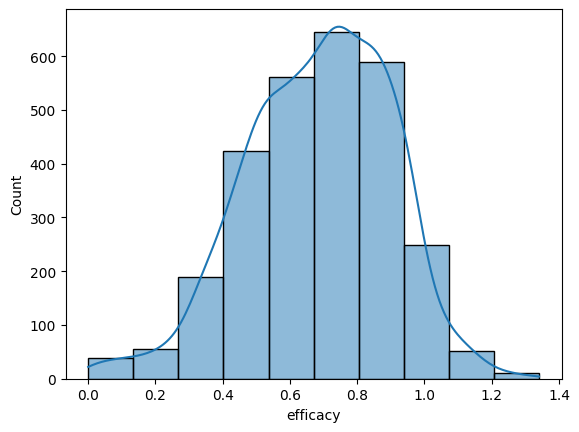

In [3]:
sns.histplot(dataset, x="efficacy", kde=True, bins=10)

# Leave One Target Out

In [5]:
rows = []
outpath = "LOGO_outfolder/"
for filename in os.listdir(outpath):
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)

        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append(
                        {
                            "name": name,
                            "representation": filename[:-5],
                            "model": model,
                            "metric": metric,
                            "value": value,
                        }
                    )

# Build DataFrame
df = pd.DataFrame(rows)
df.head(5)

,name,representation,model,metric,value
0,BD135193,GC_count,SVC,roc_auc,0.657407
1,BD135193,GC_count,SVC,pr_auc,0.770932
2,BD135193,GC_count,SVC,precision,0.619048
3,BD135193,GC_count,SVC,recall,0.975000
4,BD135193,GC_count,SVC,fscore,0.757282


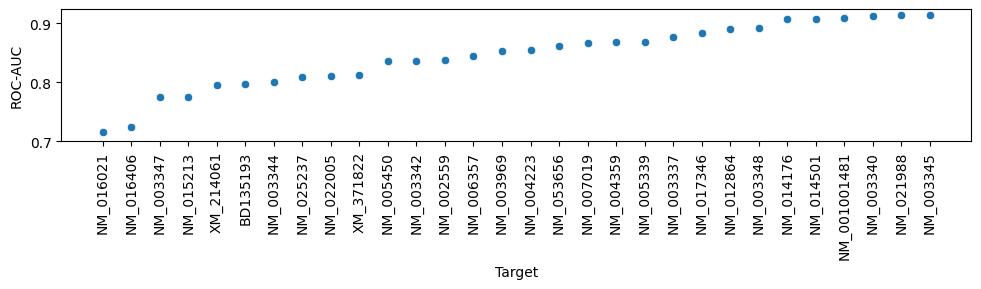

In [ ]:
filtered_df = df[
    (df["model"] == "LGR")
    & (df["representation"] == "zcurve_logo")
    & (df["metric"] == "roc_auc")
]

filtered_df = filtered_df.sort_values(by="value")
mean_roc = np.round(np.mean(filtered_df["value"]), 3)
print('Average AUC: ',mean_roc)
# Scatter line plot
plt.figure(figsize=(10, 3))
sns.scatterplot(data=filtered_df, x="name", y="value")

plt.xticks(rotation=90)
plt.xlabel("Target")
plt.ylabel("ROC-AUC")
plt.ylim(bottom=0.7)
plt.tight_layout()
plt.show()

# Ensemble

In [21]:
rows = []
outpath = "other_CV_tests/"
for filename in os.listdir(outpath):
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)

        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append(
                        {
                            "name": name,
                            "representation": filename[:-5],
                            "model": model,
                            "metric": metric,
                            "value": value,
                        }
                    )

# Build DataFrame
df = pd.DataFrame(rows)
df.head(5)

,name,representation,model,metric,value
0,BD135193,zcurve_one_hot_ensemble,VOTE,roc_auc,0.837037
1,BD135193,zcurve_one_hot_ensemble,VOTE,pr_auc,0.890939
2,BD135193,zcurve_one_hot_ensemble,VOTE,precision,0.739130
3,BD135193,zcurve_one_hot_ensemble,VOTE,recall,0.850000
4,BD135193,zcurve_one_hot_ensemble,VOTE,fscore,0.790698


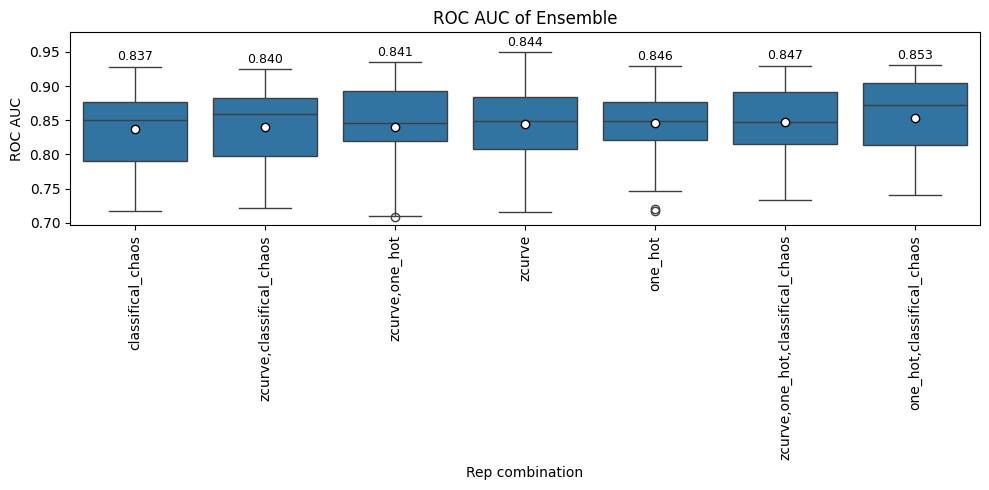

In [37]:
reps = ['zcurve', 'one_hot', 'classifical_chaos']  # <- put your actual rep names here

# longest names first so 'rep_a_b' isn't matched as 'rep_a'
# lookarounds ensure a match sits between underscores / string edges
alt = '|'.join(sorted(map(re.escape, reps), key=len, reverse=True))
pattern = re.compile(rf'(?<![^_])(?:{alt})(?![^_])')

sub = df[(df['metric'] == 'roc_auc') & (df['model'] == 'VOTE')].copy()

def extract_reps(row):
    name = row['representation']
    suffix = '_ensemble'
    if name.endswith(suffix):          # drop the model part
        name = name[:-len(suffix)]
    return ','.join(pattern.findall(name))

sub['reps'] = sub.apply(extract_reps, axis=1)

stats = sub.groupby('reps')['value'].agg(['mean', 'max']).sort_values('mean')
order = stats.index.tolist()

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=sub, x='reps', y='value', order=order, ax=ax,
            showmeans=True,
            meanprops={'marker': 'o', 'markerfacecolor': 'white',
                       'markeredgecolor': 'black'})

pad = (sub['value'].max() - sub['value'].min()) * 0.02
for i, (m, mx) in enumerate(zip(stats['mean'], stats['max'])):
    ax.text(i, mx + pad, f'{m:.3f}', ha='center', va='bottom', fontsize=9)

ax.set_xlabel('Rep combination')
ax.set_ylabel('ROC AUC')
ax.set_title('ROC AUC of Ensemble')
ax.tick_params(axis='x', rotation=90)
ax.set_ylim(top=sub['value'].max() + pad * 6)  # room for labels
plt.tight_layout()
plt.savefig('images/ensemble_top3.pdf')
plt.show()

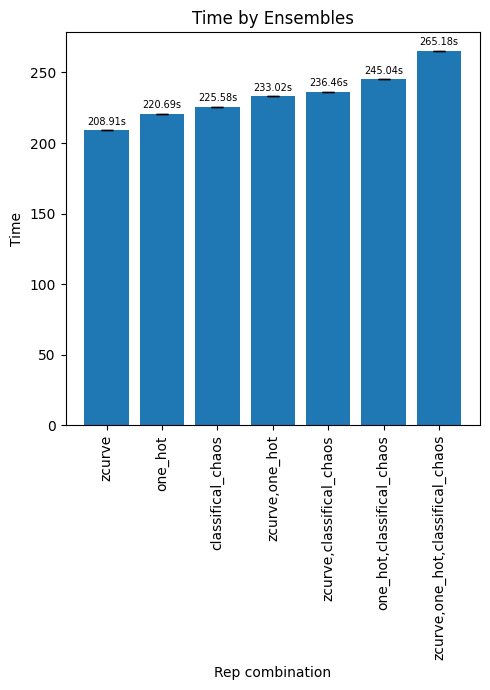

In [38]:
time_df=pd.read_csv('other_CV_tests/ensemble_time.csv')
time_df['reps'] = time_df['Rep'].apply(lambda n: ','.join(pattern.findall(n)))

stats = time_df.groupby('reps')['Time'].agg(['mean', 'std']).sort_values('mean')
stats['std'] = stats['std'].fillna(0)

fig, ax = plt.subplots(figsize=(5, 7))
bars = ax.bar(stats.index, stats['mean'], yerr=stats['std'], capsize=4)

pad = stats['mean'].max() * 0.01
for bar, m, s in zip(bars, stats['mean'], stats['std']):
    ax.text(bar.get_x() + bar.get_width() / 2, m + s + pad,
            f'{m:.2f}s', ha='center', va='bottom', fontsize=7)

ax.set_xlabel('Rep combination')
ax.set_ylabel('Time')
ax.set_title('Time by Ensembles')
ax.tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.savefig('images/ensemble_top3_time.pdf')
plt.show()


# Cluster Out

In [47]:
rows = []
outpath = "other_CV_tests/"
for filename in os.listdir(outpath):
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)

        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append(
                        {
                            "name": name,
                            "representation": filename[:-5],
                            "model": model,
                            "metric": metric,
                            "value": value,
                        }
                    )

# Build DataFrame
df = pd.DataFrame(rows)

df.head(2)

,name,representation,model,metric,value
0,50_1,zcurve_databound,SVC,roc_auc,0.614901
1,50_1,zcurve_databound,SVC,pr_auc,0.618184


Average AUC:  0.816


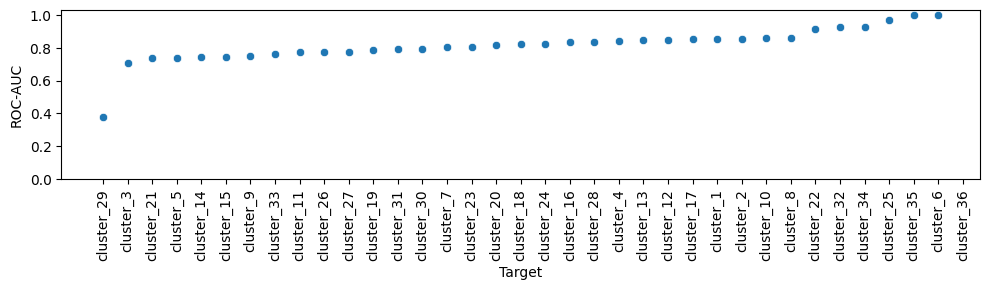

In [48]:
filtered_df = df[
    (df["model"] == "LGR")
    & (df["representation"] == "zcurve_loco")
    & (df["metric"] == "roc_auc")
]

filtered_df = filtered_df.sort_values(by="value")
mean_roc = np.round(np.mean(filtered_df["value"]), 3)
print('Average AUC: ',mean_roc)
# Scatter line plot
plt.figure(figsize=(10, 3))
sns.scatterplot(data=filtered_df, x="name", y="value")

plt.xticks(rotation=90)
plt.xlabel("Target")
plt.ylabel("ROC-AUC")
plt.ylim(bottom=0)
plt.tight_layout()
plt.savefig('Cluster_run.pdf')
plt.show()

251     AAAACCTAACAGTTGGTGGTT
814     GAAACCAAATGGGTGGTCTTT
1463    ACATGAAAATAACGGGCGTTG
1464    ATGAAAATAACGGGCGTTGCT
1825    GAAAACAAAGGCTCTCTGGTT
1892    AAGGAAAACAAAGGCTCTCTG
Name: siRNA_seq, dtype: object
Unique targets: ['NM_003337' 'NM_003345' 'NM_003348' 'XM_214061']


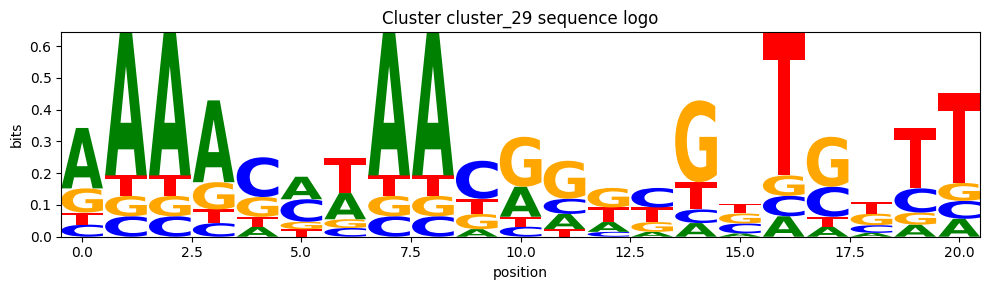

In [49]:
import pandas as pd
from Bio import Align

df = pd.read_csv("clustered.csv")          # columns: sequence, cluster, target
cluster = 'cluster_29'

sub = df[df["Cluster"] == cluster]
print(sub['siRNA_seq'])
print("Unique targets:", sub["B"].unique())

# similarity region: align all sequences to the longest one
seqs = sub["siRNA_seq"].str.upper().tolist()
ref = max(seqs, key=len)
aligner = Align.PairwiseAligner(mode="global", end_gap_score=0)

aligned = []
for s in seqs:
    row = ["-"] * len(ref)
    aln = aligner.align(ref, s)[0]
    for (rs, re), (qs, qe) in zip(*aln.aligned):
        for i, j in zip(range(rs, re), range(qs, qe)):
            row[i] = s[j]
    aligned.append("".join(row))

mat = logomaker.alignment_to_matrix(aligned, to_type="information", characters_to_ignore="-")

is_rna = set(ref) <= set("ACGTUN")
logomaker.Logo(mat, color_scheme="classic" if is_rna else "chemistry",
               figsize=(max(10, len(ref) * 0.3), 3))
plt.title(f"Cluster {cluster} sequence logo")
plt.ylabel("bits")
plt.xlabel("position")
plt.tight_layout()
plt.savefig('cluster29_logo.pdf')
plt.show()


# Threshold wise

In [50]:
rows = []
outpath = "threshold_outfolder"
for filename in os.listdir(outpath):
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)

        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append(
                        {
                            "name": name,
                            "representation": filename[:-5],
                            "model": model,
                            "metric": metric,
                            "value": value,
                        }
                    )

# Build DataFrame
df = pd.DataFrame(rows)

df.head(2)

,name,representation,model,metric,value
0,BD135193,zcurvelabel80_logo,SVC,roc_auc,0.778788
1,BD135193,zcurvelabel80_logo,SVC,pr_auc,0.646040


/tmp/ipykernel_2865451/2119567776.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df["representation"] = filtered_df["representation"].astype(str).str.extract(r"(\d+)", expand=False)


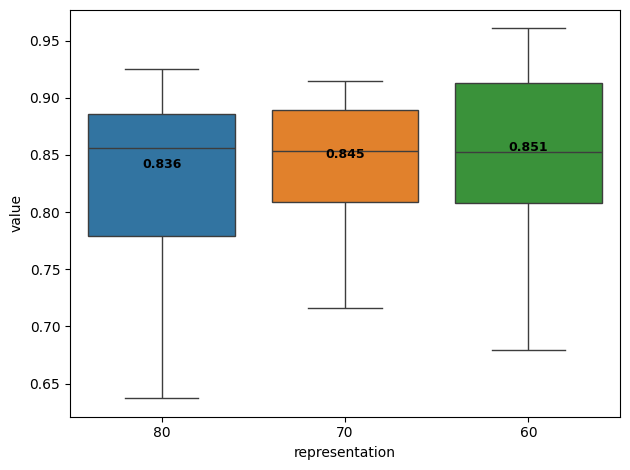

In [51]:
filtered_df = df[
    (df["model"] == "LGR")
    & (df["metric"] == "roc_auc")
]

filtered_df["representation"] = filtered_df["representation"].astype(str).str.extract(r"(\d+)", expand=False)
ax = sns.boxplot(data=filtered_df, x="representation", y="value", hue="representation")

means = filtered_df.groupby("representation", sort=False)["value"].mean()
order = [t.get_text() for t in ax.get_xticklabels()]
for i, name in enumerate(order):
    ax.text(i, means[name], f"{means[name]:.3f}", ha="center", va="bottom",
            fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig('Threshold_based_run.pdf')
plt.show()

# Sliding Window

In [2]:
rows = []
outpath = "sliding_window_outfolder/"
for filename in os.listdir(outpath):
    if filename.startswith("len"):  # process only JSON files
        filepath = os.path.join(outpath, filename)
        #print(filepath)
        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append(
                        {
                            "name": name,
                            "win_len": (b := filename[:-5]).split("_")[1],
                            "window_start": int((b := filename[:-5]).split("_")[3]) + 1,
                            "model": model,
                            "metric": metric,
                            "value": value,
                        }
                    )

# Build DataFrame
df = pd.DataFrame(rows)
df = df[(df["model"] == "LGR") & (df["metric"] == "roc_auc")]
df_avg = df.groupby(["win_len", "window_start"])["value"].mean().reset_index()
df_avg.head(5)
df.head(2)

,name,win_len,window_start,model,metric,value
10,BD135193,3,5,LGR,roc_auc,0.506481
45,NM_001001481,3,5,LGR,roc_auc,0.785714


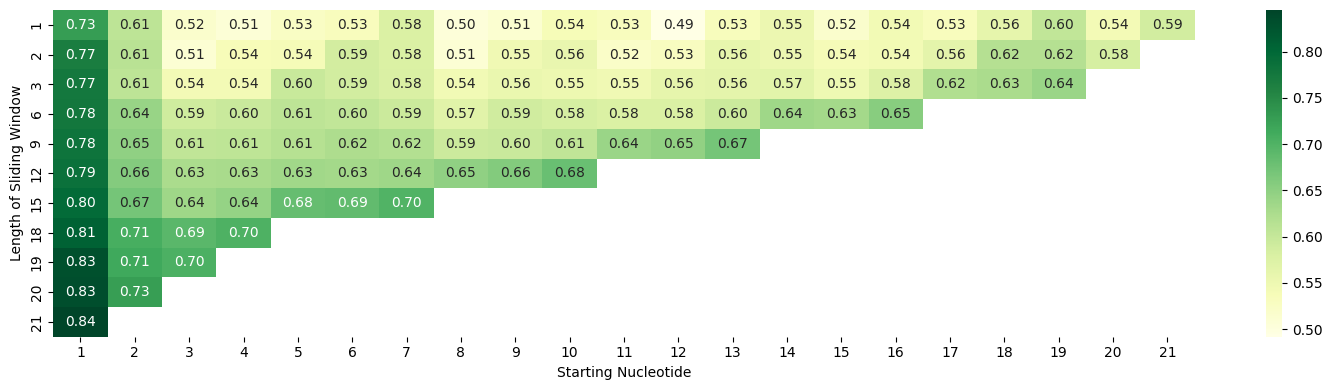

In [4]:

heatmap_data = df_avg.pivot(index="win_len", columns="window_start", values="value")
heatmap_data.index = heatmap_data.index.astype(int)
heatmap_data.columns = heatmap_data.columns.astype(int)

heatmap_data = heatmap_data.sort_index().sort_index(axis=1)

plt.figure(figsize=(15, 4))
sns.heatmap(
    heatmap_data,
    cmap="YlGn",
    annot=True,
    fmt=".2f",  # format (2 decimal places)
)

plt.xlabel("Starting Nucleotide")
plt.ylabel("Length of Sliding Window")
plt.tight_layout()
plt.savefig('images/sliding_window_results.pdf')
plt.show()

In [12]:
with open("sliding_window_outfolder/Predictions_len_1_win_0_1.json") as f:
    data = json.load(f)

svc_dfs = {}
for group, content in data.items():
    # skip non-group entries like "representations"
    if isinstance(content, dict) and "LGR" in content:
        svc_dfs[group] = pd.DataFrame(content["LGR"], columns=["Pred", "Index"])

combined = pd.concat(svc_dfs, names=["Target"]).reset_index(level=0).reset_index(drop=True)
combined.head(5)

,Target,Pred,Index
0,BD135193,0.0,0
1,BD135193,1.0,1
2,BD135193,0.0,2
3,BD135193,0.0,3
4,BD135193,0.0,4


In [13]:
dataset = pd.read_csv("raw_data/All_Dataset.csv")
huesken = dataset[dataset["sources"] == "Huesken"]
combined = combined.set_index("Index")
combined[["Label", "siRNA_seq", 'Ref target']] = huesken.loc[combined.index, ["Label", "siRNA_seq", 'B']].values
combined['First nucleotide']=combined['siRNA_seq'].str[0]
combined = combined.reset_index()
combined.head(5)

,Index,Target,Pred,Label,siRNA_seq,Ref target,First nucleotide
0,0,BD135193,0.0,0.0,CTAATATGTTAATTGATTTAT,BD135193,C
1,1,BD135193,1.0,0.0,AATATGTTAATTGATTTATAC,BD135193,A
2,2,BD135193,0.0,0.0,GATTTATACAATTCCTTTCAA,BD135193,G
3,3,BD135193,0.0,0.0,CAATTCCTTTCAATTTTATCT,BD135193,C
4,4,BD135193,0.0,0.0,CAGACCAAAATTAAATAAGAA,BD135193,C


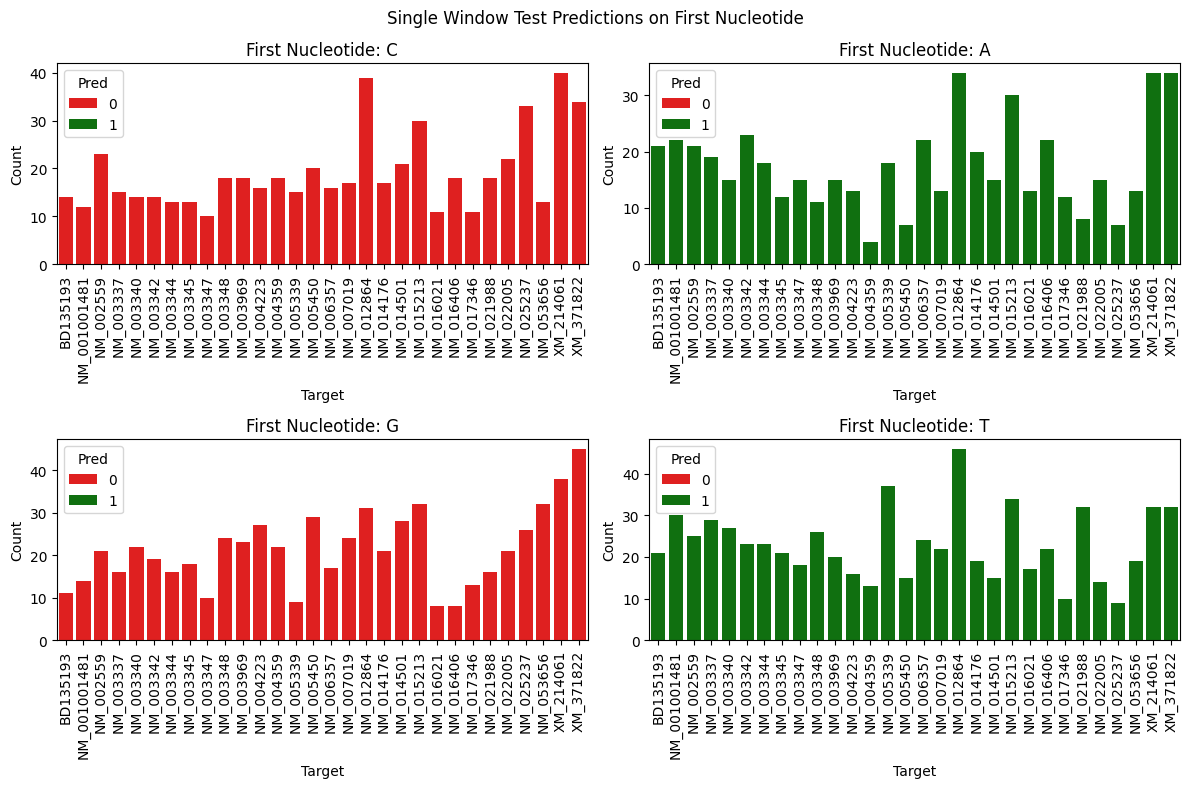

In [19]:
chars = combined['First nucleotide'].unique()[:4]
target_order = sorted(combined['Target'].unique())
palette = {0: 'red', 1: 'green'}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, ch in zip(axes.flat, chars):
    sns.countplot(
        data=combined[combined['First nucleotide'] == ch],
        x='Target', hue='Pred',
        order=target_order, hue_order=[0, 1],
        palette=palette, ax=ax
    )
    ax.set_title(f'First Nucleotide: {ch}')
    ax.set_xlabel('Target')
    ax.tick_params(axis='x', rotation=90)
    ax.set_ylabel('Count')
    ax.legend(title='Pred')
plt.suptitle('Single Window Test Predictions on First Nucleotide')
plt.tight_layout()
plt.savefig('images/First_Nuc_Association.pdf')
plt.show()

# Databound Test

In [15]:
rows = []
outpath = "other_CV_tests/"
for filename in os.listdir(outpath):
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)

        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append(
                        {
                            "name": name,
                            "representation": filename[:-5],
                            "model": model,
                            "metric": metric,
                            "value": value,
                        }
                    )

# Build DataFrame
df = pd.DataFrame(rows)

df.head(2)

,name,representation,model,metric,value
0,50_1,zcurve_databound,SVC,roc_auc,0.614901
1,50_1,zcurve_databound,SVC,pr_auc,0.618184


In [16]:
filtered_df = df[(df["model"] == "LGR") & (df["representation"] == "zcurve_databound")]

filtered_df["name"] = filtered_df["name"].str.extract(r"^([^_]+)").astype(int)

filtered_df.head(2)

/tmp/ipykernel_2083974/2111086880.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df["name"] = filtered_df["name"].str.extract(r"^([^_]+)").astype(int)


,name,representation,model,metric,value
10,50,zcurve_databound,LGR,roc_auc,0.640358
11,50,zcurve_databound,LGR,pr_auc,0.646982


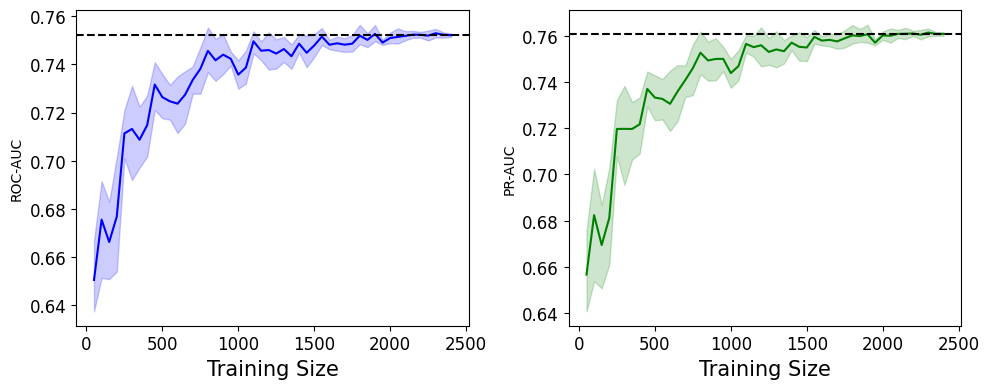

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False, sharex=True)
roc_df = filtered_df[filtered_df["metric"] == "roc_auc"]
sns.lineplot(data=roc_df, x="name", y="value", ax=axes[0], color="Blue", errorbar="ci")
axes[0].axhline(roc_df.loc[roc_df["name"] == 2400, "value"].mean(), ls="--", c="Black")
axes[0].set_xlabel("Training Size", size=15)
axes[0].tick_params(axis="y", labelsize=12)
axes[0].set_ylabel("ROC-AUC")
axes[0].tick_params(axis="x", labelsize=12)
pr_df = filtered_df[filtered_df["metric"] == "pr_auc"]
sns.lineplot(data=pr_df, x="name", y="value", ax=axes[1], color="Green", errorbar="ci")
axes[1].axhline(pr_df.loc[pr_df["name"] == 2400, "value"].mean(), ls="--", c="Black")
axes[1].set_xlabel("Training Size", size=15)
axes[1].tick_params(axis="x", labelsize=12)
axes[1].tick_params(axis="y", labelsize=12)
axes[1].set_ylabel("PR-AUC")
plt.tight_layout()
plt.show()

# SOTA

In [35]:
rows = []
outpath = "LOGO_outfolder/"
for filename in os.listdir(outpath):
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)

        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append(
                        {
                            "name": name,
                            "representation": filename[:-5],
                            "model": model,
                            "metric": metric,
                            "value": value,
                        }
                    )

# Build DataFrame
df = pd.DataFrame(rows)
df.drop(df[df["representation"] == "zcurve_repeat"].index, inplace=True)
df["model"] = df["model"].replace("RF", "Random Forest")
df["model"] = df["model"].replace("LGR", "Logistic Regression")
df["model"] = df["model"].replace("DT", "Decision Tree")
df["model"] = df["model"].replace("SGD", "Stochastic Gradient Descent")
df["model"] = df["model"].replace("KNN", "K-Nearest Neighbour")
df["model"] = df["model"].replace("XGB", "XG Boost")
df

,name,representation,model,metric,value
0,BD135193,GC_count,SVC,roc_auc,0.657407
1,BD135193,GC_count,SVC,pr_auc,0.770932
2,BD135193,GC_count,SVC,precision,0.619048
3,BD135193,GC_count,SVC,recall,0.975000
4,BD135193,GC_count,SVC,fscore,0.757282
...,...,...,...,...,...
12595,XM_371822,atomic_number,Stochastic Gradient Descent,roc_auc,0.496036
12596,XM_371822,atomic_number,Stochastic Gradient Descent,pr_auc,0.377137
12597,XM_371822,atomic_number,Stochastic Gradient Descent,precision,0.303030
12598,XM_371822,atomic_number,Stochastic Gradient Descent,recall,0.172414


In [43]:
logo_our = df[
    (df["model"] == "Logistic Regression")
    & (df["representation"] == "zcurve")
    & (df["metric"] == "roc_auc")
]
logo_our = logo_our[["name", "value"]]
logo_our.columns = ["Target", "AUC"]
logo_our.head(3)

,Target,AUC
6310,BD135193,0.796296
6345,NM_001001481,0.909457
6380,NM_002559,0.837451


In [44]:
logo_oligoformer = pd.read_csv(
    "/ceph/users/ahm22224/siRNA_projects/publication_work/siRNA_unmod_paper/siRNA_unmod_compare/OligoFormer/LOGO_results.csv"
)
logo_oligoformer.head(3)

,Unnamed: 0,Target,ROC-AUC
0,0,BD135193,0.689815
1,1,NM_001001481,0.814889
2,2,NM_002559,0.779150


In [45]:
logo_sirnadisc = pd.read_csv(
    "/ceph/users/ahm22224/siRNA_projects/publication_work/siRNA_unmod_paper/siRNA_unmod_compare/siRNADiscovery/logo_split/Results.csv"
)
logo_sirnadisc.head(3)

,Unnamed: 0,AUC,Target
0,0,0.869444,BD135193
1,1,0.909457,NM_001001481
2,2,0.839427,NM_002559


In [46]:
dfs = [
    logo_our.set_index("Target")["AUC"],
    logo_oligoformer.set_index("Target")["ROC-AUC"],
    logo_sirnadisc.set_index("Target")["AUC"],
]
final = pd.concat(
    dfs, axis=1, keys=["SiGMA", "Oligoformer", "siRNADiscovery"]
).reset_index()
final.head(5)

,Target,SiGMA,Oligoformer,siRNADiscovery
0,BD135193,0.796296,0.689815,0.869444
1,NM_001001481,0.909457,0.814889,0.909457
2,NM_002559,0.837451,0.779150,0.839427
3,NM_003337,0.877470,0.837945,0.903162
4,NM_003340,0.912500,0.913441,0.941667


In [47]:
final.mean(numeric_only=True)

SiGMA             0.844843
Oligoformer       0.801783
siRNADiscovery    0.864988
dtype: float64

0.009383219076912159 0.8968972564734934


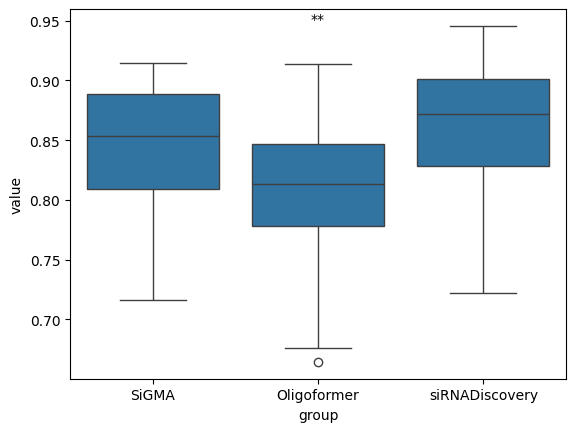

In [48]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

# p-values
p2 = mannwhitneyu(final["SiGMA"], final["Oligoformer"],alternative='greater',nan_policy='omit').pvalue
p3 = mannwhitneyu(final["SiGMA"], final["siRNADiscovery"],alternative='greater',nan_policy='omit').pvalue
print(p2,p3)

# reshape for seaborn
plot_df = final.melt(
    value_vars=["SiGMA", "Oligoformer", "siRNADiscovery"],
    var_name="group",
    value_name="value",
)

ax = sns.boxplot(data=plot_df, x="group", y="value")


# star helper
def star(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""


y = plot_df["value"].max()

# add stars only above b2 / b3 if significant
if star(p2):
    ax.text(1, y, star(p2), ha="center", va="bottom")

if star(p3):
    ax.text(2, y, star(p3), ha="center", va="bottom")
plt.savefig("Comparison.pdf")
plt.savefig("Comparison.eps")
plt.show()

In [49]:
rows = []
outpath = "LOGO_outfolder/"
for filename in os.listdir(outpath):
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)

        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append(
                        {
                            "name": name,
                            "representation": filename[:-5],
                            "model": model,
                            "metric": metric,
                            "value": value,
                        }
                    )

# Build DataFrame
df = pd.DataFrame(rows)
df.drop(df[df["representation"] == "zcurve_repeat"].index, inplace=True)
df["model"] = df["model"].replace("RF", "Random Forest")
df["model"] = df["model"].replace("LGR", "Logistic Regression")
df["model"] = df["model"].replace("DT", "Decision Tree")
df["model"] = df["model"].replace("SGD", "Stochastic Gradient Descent")
df["model"] = df["model"].replace("KNN", "K-Nearest Neighbour")
df["model"] = df["model"].replace("XGB", "XG Boost")
df


,name,representation,model,metric,value
0,BD135193,GC_count,SVC,roc_auc,0.657407
1,BD135193,GC_count,SVC,pr_auc,0.770932
2,BD135193,GC_count,SVC,precision,0.619048
3,BD135193,GC_count,SVC,recall,0.975000
4,BD135193,GC_count,SVC,fscore,0.757282
...,...,...,...,...,...
12595,XM_371822,atomic_number,Stochastic Gradient Descent,roc_auc,0.496036
12596,XM_371822,atomic_number,Stochastic Gradient Descent,pr_auc,0.377137
12597,XM_371822,atomic_number,Stochastic Gradient Descent,precision,0.303030
12598,XM_371822,atomic_number,Stochastic Gradient Descent,recall,0.172414


In [50]:
logo_our = df[
    (df["model"] == "Logistic Regression")
    & (df["representation"] == "zcurve")
    & (df["metric"] == "roc_auc")
]
logo_our = logo_our[["name", "value"]]
logo_our.columns = ["Target", "AUC"]
logo_our.head(3)

,Target,AUC
6310,BD135193,0.796296
6345,NM_001001481,0.909457
6380,NM_002559,0.837451


In [51]:
biopredsi=pd.read_csv('/ceph/users/ahm22224/siRNA_projects/publication_work/siRNA_unmod_paper/siRNA_unmod_compare/biopredsi.csv')
iscore=pd.read_csv('/ceph/users/ahm22224/siRNA_projects/publication_work/siRNA_unmod_paper/siRNA_unmod_compare/iscore.csv')

In [53]:
dfs = [
    logo_our.set_index("Target")["AUC"],
    biopredsi.set_index("Target")["ROC"],
    iscore.set_index("Target")["ROC"],
]
final = pd.concat(
    dfs, axis=1, keys=["SiGMA", "Biopredsi", "i-score"]
).reset_index()
final.head(5)

,Target,SiGMA,Biopredsi,i-score
0,BD135193,0.796296,0.6361,0.7250
1,NM_001001481,0.909457,0.5976,0.8913
2,NM_002559,0.837451,0.7599,0.8295
3,NM_003337,0.877470,0.7655,0.8676
4,NM_003340,0.912500,0.8063,0.8972
